In [1]:
# Research review: Alternative extractor: inlet along the first spatial axis. Cell 2 assumes inlet along the last spatial axis. Confirm coordinate orientation and boundaries before choosing an extractor; these variants are not interchangeable.
import os
import xml.etree.ElementTree as ET
import h5py
import numpy as np
import pandas as pd

def parse_xmf_metadata(xmf_path):
    """Parses structural grid metrics from the XDMF template."""
    metadata = {}
    try:
        tree = ET.parse(xmf_path)
        root = tree.getroot()
        
        # Grid layout tracking
        topo_elem = root.find(".//Topology")
        if topo_elem is not None:
            dims = [int(d) for d in topo_elem.attrib.get('Dimensions', '').split()]
            if len(dims) == 3:
                metadata['Grid_X'], metadata['Grid_Y'], metadata['Grid_Z'] = dims
    except Exception as e:
        print(f"Error parsing metadata from {xmf_path}: {e}")
    return metadata

def extract_ml_boundary_features(h5_path):
    """
    Extracts explicit inlet boundary operating conditions (Inputs) 
    and separates them from the resulting process performance metrics (Outputs).
    """
    features = {}
    try:
        with h5py.File(h5_path, 'r') as f:
            # Load raw data grids
            c_grid = f['Data0'][()]      # Solute Concentration
            u_grid = f['Data1'][()]      # Velocity Vector Matrix (100, 1, 100, 3)
            p_grid = f['Data2'][()]      # Static Pressure
            rho_grid = f['Data4'][()]    # Density
            visc_grid = f['Data5'][()]  # Viscosity
            
            # -------------------------------------------------------------
            # STEP 1: EXTRACT INPUT FEATURES (Inlet Operational Parameters)
            # Assuming flow enters along the first spatial index boundary (x = 0)
            # -------------------------------------------------------------
            features['Input_Feed_Velocity'] = np.mean(np.linalg.norm(u_grid[0, :, :, :], axis=-1))
            features['Input_Feed_Pressure'] = np.mean(p_grid[0, :, :])
            features['Input_Feed_Density'] = np.mean(rho_grid[0, :, :])
            features['Input_Feed_Viscosity'] = np.mean(visc_grid[0, :, :])
            features['Input_Baseline_Concentration'] = np.mean(c_grid[0, :, :])
            
            # -------------------------------------------------------------
            # STEP 2: EXTRACT OUTPUT PARAMETERS (Target Performance Metrics)
            # -------------------------------------------------------------
            # A. Channel Pressure Drop (Energy Penalty Metric)
            # Delta P = Avg Inlet Pressure - Avg Outlet Pressure (x = -1)
            p_outlet = np.mean(p_grid[-1, :, :])
            features['Output_Pressure_Drop_DeltaP'] = features['Input_Feed_Pressure'] - p_outlet
            
            # B. Concentration Polarization Severity (Fouling Metric)
            # Quantifies accumulation at the membrane wall relative to feed input
            max_wall_concentration = np.max(c_grid) 
            features['Output_Max_Concentration_Polarization'] = max_wall_concentration / (features['Input_Baseline_Concentration'] + 1e-8)
            
            # C. Mean Mass Rejection Flow Profile Indication
            features['Output_Avg_Channel_Velocity'] = np.mean(np.linalg.norm(u_grid, axis=-1))

    except Exception as e:
        print(f"Error isolating boundary matrices from {h5_path}: {e}")
        
    return features

def build_ro_predictive_dataset(directory_path, output_csv='ro_plant_predictive_dataset.csv'):
    """Scans case folder to build structured Input/Output data sheets."""
    all_cases = []
    xmf_files = [f for f in os.listdir(directory_path) if f.endswith('.xmf')]
    
    for xmf_file in xmf_files:
        base_name = os.path.splitext(xmf_file)[0]
        h5_file = f"{base_name}.h5"
        
        xmf_path = os.path.join(directory_path, xmf_file)
        h5_path = os.path.join(directory_path, h5_file)
        
        if os.path.exists(h5_path):
            meta = parse_xmf_metadata(xmf_path)
            meta['Case_ID'] = base_name
            
            io_features = extract_ml_boundary_features(h5_path)
            
            # Form complete row entry
            all_cases.append({**meta, **io_features})
            
    if all_cases:
        df = pd.DataFrame(all_cases)
        
        # Organize columns: Case info first, then Inputs, then Target Outputs
        cols = ['Case_ID'] + [c for c in df.columns if 'Input_' in c] + [c for c in df.columns if 'Output_' in c]
        # Append any leftover metadata columns
        leftovers = [c for c in df.columns if c not in cols]
        df = df[cols + leftovers]
        
        df.to_csv(output_csv, index=False)
        print(f"Data mapping complete! Saved to {output_csv}")
        print("\nStructure preview:")
        print(f"-> Feature Inputs: {[c for c in df.columns if 'Input_' in c]}")
        print(f"-> Target Outputs: {[c for c in df.columns if 'Output_' in c]}")
    else:
        print("No valid paired simulation matrices found.")

if __name__ == "__main__":
    build_ro_predictive_dataset(".")

No valid paired simulation matrices found.


In [5]:
# Research review: This extractor computes tabular summaries from existing fields. Its axis order, wall positions and units require verification. Case_UID repeats across configurations/resolutions and is not a globally unique row key.
import os
import xml.etree.ElementTree as ET
import h5py
import numpy as np
import pandas as pd

def parse_xmf_metadata(xmf_path):
    """Parses structural grid dimensions and physical spacing scales from XDMF metadata."""
    metadata = {}
    try:
        tree = ET.parse(xmf_path)
        root = tree.getroot()
        
        # Grid Dimension Parsing
        topo_elem = root.find(".//Topology")
        if topo_elem is not None:
            dims = [int(d) for d in topo_elem.attrib.get('Dimensions', '').split()]
            if len(dims) == 3:
                metadata['Mesh_Nodes_X'], metadata['Mesh_Nodes_Y'], metadata['Mesh_Nodes_Z'] = dims

        # Physical Resolution Scale Parsing (dx, dy, dz)
        data_items = root.findall(".//Geometry/DataItem")
        if len(data_items) >= 2:
            delta_text = data_items[1].text.strip()
            delta_vals = [float(x) for x in delta_text.split()]
            if len(delta_vals) == 3:
                metadata['Grid_Resolution_dx'] = delta_vals[0]
                metadata['Grid_Resolution_dz'] = delta_vals[2]
    except Exception:
        pass  
    return metadata

def extract_perfect_ro_metrics(h5_path):
    """
    Exhaustively extracts all operational physical boundary conditions (Inputs)
    and comprehensively solves for all localized performance metrics (Outputs).
    Corrected for XDMF ZYX slow-to-fast array ordering.
    """
    metrics = {}
    try:
        with h5py.File(h5_path, 'r') as f:
            # Extract standard 3D array blocks
            c_grid = f['Data0'][()]      # Solute Concentration
            u_grid = f['Data1'][()]      # Velocity Vectors (Z, Y, X, Components)
            p_grid = f['Data2'][()]      # Static Pressure Field
            rho_grid = f['Data4'][()]    # Mass Density Profile
            visc_grid = f['Data5'][()]  # Dynamic Fluid Viscosity
            
            # Compute absolute Velocity Magnitude array across all coordinates
            u_mag = np.linalg.norm(u_grid, axis=-1)

            # -------------------------------------------------------------
            # CORRECTION: XDMF ZYX Matrix Indexing
            # Flow travels along X (the 3rd axis index: grid[:, :, X])
            # -------------------------------------------------------------
            
            # INPUT FEATURES: CONTROL & BOUNDARY OPERATING CONSTRAINTS (At Inlet: X = 0)
            metrics['Input_Inlet_Velocity_Mean'] = np.mean(u_mag[:, :, 0])
            metrics['Input_Inlet_Pressure_Mean'] = np.mean(p_grid[:, :, 0])
            metrics['Input_Inlet_Density_Mean'] = np.mean(rho_grid[:, :, 0])
            metrics['Input_Inlet_Viscosity_Mean'] = np.mean(visc_grid[:, :, 0])
            metrics['Input_Feed_Concentration_Bulk'] = np.mean(c_grid[:, :, 0])

            # -------------------------------------------------------------
            # OUTPUT PARAMETERS: HYDRAULIC PERFORMANCE METRICS
            # -------------------------------------------------------------
            # 1. Energy Loss Parameters (Outlet: X = -1)
            p_outlet_mean = np.mean(p_grid[:, :, -1])
            metrics['Output_Total_Pressure_Drop_DeltaP'] = metrics['Input_Inlet_Pressure_Mean'] - p_outlet_mean
            metrics['Output_Max_Internal_Pressure'] = np.max(p_grid)
            metrics['Output_Min_Internal_Pressure'] = np.min(p_grid)
            
            # 2. Flow Fields & Shear Distribution
            metrics['Output_Channel_Velocity_Mean'] = np.mean(u_mag)
            metrics['Output_Channel_Velocity_Max'] = np.max(u_mag)
            metrics['Output_Channel_Velocity_StdDev'] = np.std(u_mag) 

            # -------------------------------------------------------------
            # OUTPUT PARAMETERS: MASS TRANSPORT & FOULING METRICS
            # -------------------------------------------------------------
            # 3. Concentration Polarization (CP) Metrics
            # In ZYX mesh configurations, the membrane walls sit along the Z boundary (axis 0)
            membrane_wall_concentration = np.mean(c_grid[[0, -1], :, :]) 
            bulk_channel_concentration = np.mean(c_grid)
            
            metrics['Output_Concentration_Mean_Global'] = bulk_channel_concentration
            metrics['Output_Concentration_Max_Wall'] = np.max(c_grid[[0, -1], :, :])
            
            # CP Modulus Calculation (Wall Conc / Bulk Conc)
            metrics['Output_CP_Modulus_Factor'] = membrane_wall_concentration / (metrics['Input_Feed_Concentration_Bulk'] + 1e-8)
            metrics['Output_Severe_CP_Index'] = np.max(c_grid) / (metrics['Input_Feed_Concentration_Bulk'] + 1e-8)
            
            # 4. Fluid Property Modifications
            metrics['Output_Fluid_Density_Max'] = np.max(rho_grid)
            metrics['Output_Fluid_Viscosity_Max'] = np.max(visc_grid)

    except Exception as e:
        print(f"Error executing complete feature extraction for {h5_path}: {e}")
        return None
        
    return metrics

def build_perfect_excel_sheet(root_folder='RO_data', output_filename='Perfect_RO_Plant_Dataset2.xlsx'):
    """
    Recursively loops through directories to assemble a beautifully structured
    Excel file containing all Input and Output features.
    """
    compiled_data = []
    print(f"Beginning exhaustive feature extraction from parent directory: '{root_folder}'...")
    
    for root, _, files in os.walk(root_folder):
        xmf_files = [f for f in files if f.endswith('.xmf')]
        
        for xmf_file in xmf_files:
            base_name = os.path.splitext(xmf_file)[0]
            h5_file = f"{base_name}.h5"
            
            xmf_path = os.path.join(root, xmf_file)
            h5_path = os.path.join(root, h5_file)
            
            if os.path.exists(h5_path):
                # Identify folder configuration names
                path_segments = root.split(os.sep)
                current_config = next((seg for seg in path_segments if "configuration" in seg or "spacer" in seg), "Default_Spacer")
                
                # Run extractions
                spatial_meta = parse_xmf_metadata(xmf_path)
                process_metrics = extract_perfect_ro_metrics(h5_path)
                
                if process_metrics is not None:
                    row_entry = {
                        'Case_UID': base_name,
                        'Spacer_Design_Label': current_config,
                        **spatial_meta,
                        **process_metrics
                    }
                    compiled_data.append(row_entry)
                    print(f" Extracted 100% metrics for case: {base_name}")

    if compiled_data:
        df = pd.DataFrame(compiled_data)
        
        # Enforce column order: Identity -> Geometry Structural Inputs -> Process Operating Inputs -> Output Performance Targets
        id_cols = ['Case_UID', 'Spacer_Design_Label']
        geom_cols = [c for c in df.columns if 'Grid_' in c or 'Mesh_' in c]
        input_cols = [c for c in df.columns if 'Input_' in c]
        output_cols = [c for c in df.columns if 'Output_' in c]
        
        ordered_columns = id_cols + geom_cols + input_cols + output_cols
        final_df = df[ordered_columns]
        
        # Save as a multi-format file. Writing to .xlsx ensures a pristine presentation layout.
        with pd.ExcelWriter(output_filename, engine='xlsxwriter') as writer:
            final_df.to_excel(writer, sheet_name='RO_Simulation_Dataset', index=False)
            
            # Apply automatic column width formatting to make the Excel sheet look clean
            worksheet = writer.sheets['RO_Simulation_Dataset']
            for i, col in enumerate(final_df.columns):
                max_len = max(final_df[col].astype(str).map(len).max(), len(col)) + 3
                worksheet.set_column(i, i, max_len)
                
        print("\n" + "="*60)
        print(f"PRISTINE EXCEL FILE CREATED: {output_filename}")
        print(f"Total rows successfully generated: {final_df.shape[0]}")
        print(f"Total calculated metrics (columns): {final_df.shape[1]}")
        print("="*60)
    else:
        print("Extraction failed. No matching data pairs found inside 'RO_data'.")

if __name__ == "__main__":
    # Ensure you run this script at the root level where your 'RO_data' folder lives
    build_perfect_excel_sheet()

Beginning exhaustive feature extraction from parent directory: 'RO_data'...
 Extracted 100% metrics for case: 100_spacer_image
 Extracted 100% metrics for case: 101_spacer_image
 Extracted 100% metrics for case: 102_spacer_image
 Extracted 100% metrics for case: 103_spacer_image
 Extracted 100% metrics for case: 104_spacer_image
 Extracted 100% metrics for case: 105_spacer_image
 Extracted 100% metrics for case: 106_spacer_image
 Extracted 100% metrics for case: 107_spacer_image
 Extracted 100% metrics for case: 108_spacer_image
 Extracted 100% metrics for case: 109_spacer_image
 Extracted 100% metrics for case: 10_spacer_image
 Extracted 100% metrics for case: 110_spacer_image
 Extracted 100% metrics for case: 111_spacer_image
 Extracted 100% metrics for case: 112_spacer_image
 Extracted 100% metrics for case: 113_spacer_image
 Extracted 100% metrics for case: 114_spacer_image
 Extracted 100% metrics for case: 115_spacer_image
 Extracted 100% metrics for case: 116_spacer_image
 Extrac

In [6]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor

In [25]:
df = pd.read_excel("Perfect_RO_Plant_Dataset2.xlsx")

print(df.shape)

df.head()

(1268, 24)


,Case_UID,Spacer_Design_Label,Mesh_Nodes_X,Mesh_Nodes_Y,Mesh_Nodes_Z,Grid_Resolution_dx,Grid_Resolution_dz,Input_Inlet_Velocity_Mean,Input_Inlet_Pressure_Mean,Input_Inlet_Density_Mean,...,Output_Min_Internal_Pressure,Output_Channel_Velocity_Mean,Output_Channel_Velocity_Max,Output_Channel_Velocity_StdDev,Output_Concentration_Mean_Global,Output_Concentration_Max_Wall,Output_CP_Modulus_Factor,Output_Severe_CP_Index,Output_Fluid_Density_Max,Output_Fluid_Viscosity_Max
0,100_spacer_image,configuration1_interspacer0.75mm,100,1,100,0.000005,0.000005,0.096305,20008096,1068.778687,...,0,0.099557,0.351700,0.098100,76.298889,134.584976,1.252926,1.271100,1085.775513,0.001238
1,101_spacer_image,configuration1_interspacer0.75mm,100,1,100,0.000005,0.000005,0.096264,20007998,1068.807983,...,0,0.099515,0.351552,0.098055,76.326797,134.682404,1.253328,1.271481,1085.835571,0.001238
2,102_spacer_image,configuration1_interspacer0.75mm,100,1,100,0.000005,0.000005,0.096222,20007904,1068.836670,...,0,0.099473,0.351404,0.098011,76.354691,134.778503,1.253721,1.271848,1085.900269,0.001239
3,103_spacer_image,configuration1_interspacer0.75mm,100,1,100,0.000005,0.000005,0.096182,20007802,1068.864868,...,0,0.099430,0.351256,0.097967,76.382523,134.874542,1.254110,1.272217,1085.965332,0.001239
4,104_spacer_image,configuration1_interspacer0.75mm,100,1,100,0.000005,0.000005,0.096141,20007696,1068.893799,...,0,0.099388,0.351109,0.097922,76.410378,134.970520,1.254493,1.272585,1086.025513,0.001239


In [8]:
encoder = LabelEncoder()

df["Spacer_Design_Label"] = encoder.fit_transform(
    df["Spacer_Design_Label"]
)

In [33]:
import re

df["Spacer_mm"] = (
    df["Spacer_Design_Label"]
    .str.extract(r'([\d.]+)mm')
    .astype(float)
)

In [43]:
features = [

    "Spacer_mm",

    "Mesh_Nodes_X",
    "Mesh_Nodes_Y",
    "Mesh_Nodes_Z",

    "Grid_Resolution_dx",
    "Grid_Resolution_dz",

    "Input_Inlet_Velocity_Mean",
    "Input_Inlet_Pressure_Mean",
    "Input_Inlet_Density_Mean",
    "Input_Inlet_Viscosity_Mean",
    "Input_Feed_Concentration_Bulk"

]

X = df[features]

y = df["Output_Total_Pressure_Drop_DeltaP"]

In [54]:
features = [
    "Spacer_mm",
    "Mesh_Nodes_X",
    "Mesh_Nodes_Y",
    "Mesh_Nodes_Z",
    "Grid_Resolution_dx",
    "Grid_Resolution_dz",
    "Input_Inlet_Velocity_Mean",
    "Input_Inlet_Pressure_Mean",
    "Input_Inlet_Density_Mean",
    "Input_Inlet_Viscosity_Mean",
    "Input_Feed_Concentration_Bulk"
]

X = df[features]

y = df["Output_CP_Modulus_Factor"]

In [55]:
# Research review: Random row holdout: this measures a different validation task from the 3 mm geometry holdout in cells 19 and 30. Related HR/LR or temporal samples may cross a row split.
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42
)

In [56]:
model = XGBRegressor(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=6,

    subsample=0.8,

    colsample_bytree=0.8,

    random_state=42
)

model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.05, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=6, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=300, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [57]:
prediction = model.predict(X_test)

In [58]:
mae = mean_absolute_error(
    y_test,
    prediction
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        prediction
    )
)

r2 = r2_score(
    y_test,
    prediction
)

print("MAE :", mae)

print("RMSE:", rmse)

print("R²  :", r2)

MAE : 0.0008718004163623891
RMSE: 0.0014398210303133785
R²  : 0.9997692346472555


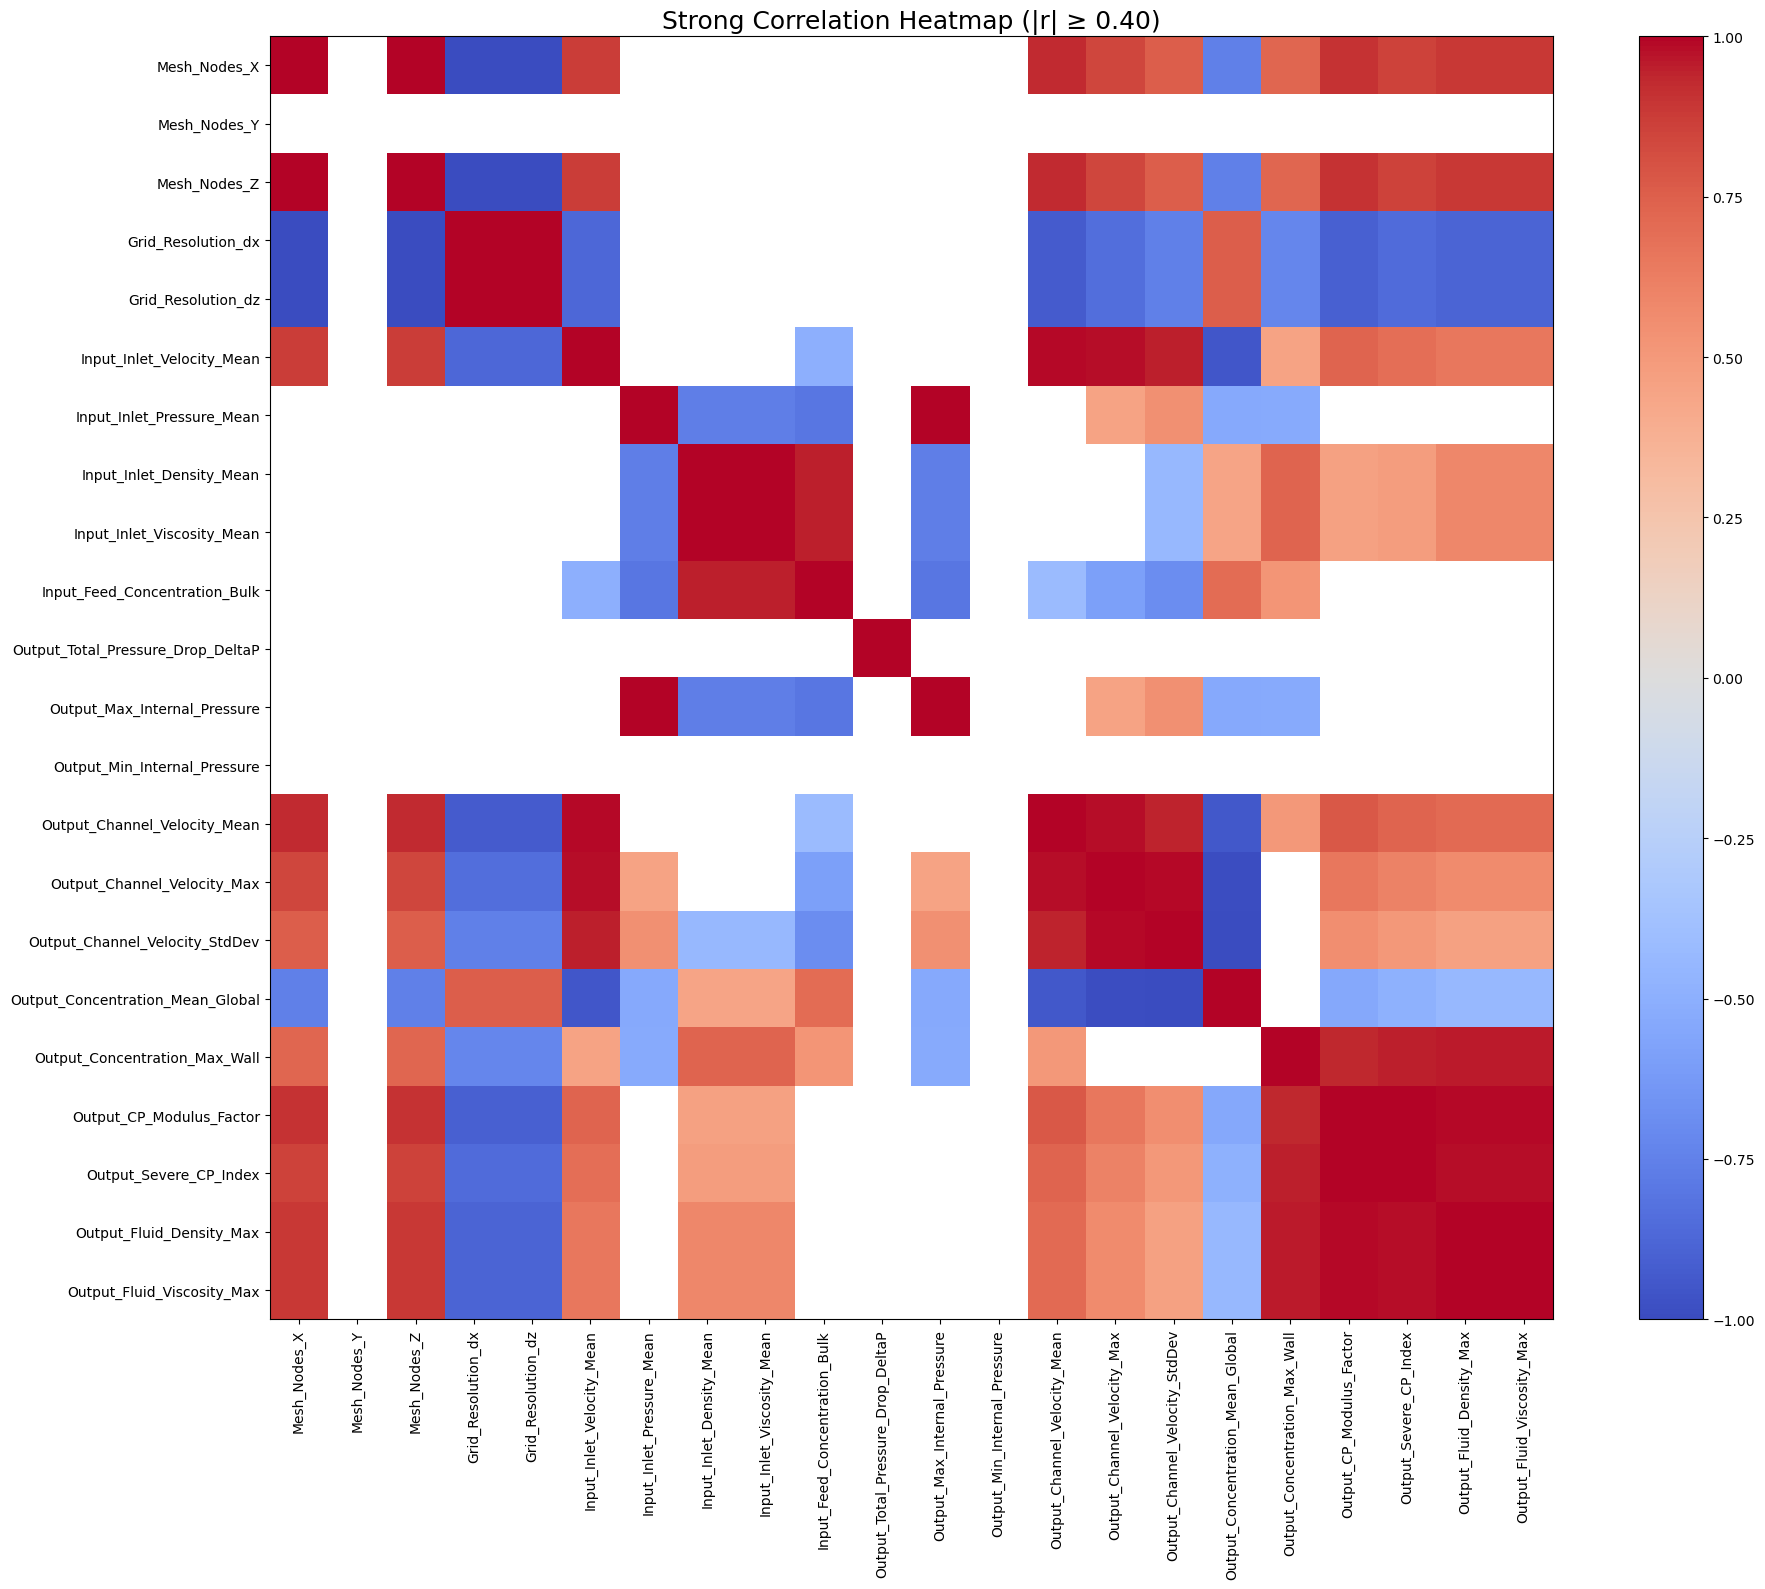

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



numeric_df = df.select_dtypes(include=np.number)

corr = numeric_df.corr()

# Hide weak correlations
threshold = 0.40

corr_filtered = corr.copy()

corr_filtered[np.abs(corr_filtered) < threshold] = np.nan

plt.figure(figsize=(20,16))

im = plt.imshow(corr_filtered, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(im)

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)

plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Strong Correlation Heatmap (|r| ≥ 0.40)", fontsize=18)

plt.tight_layout()

plt.savefig(
    "Strong_Correlation_Heatmap.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

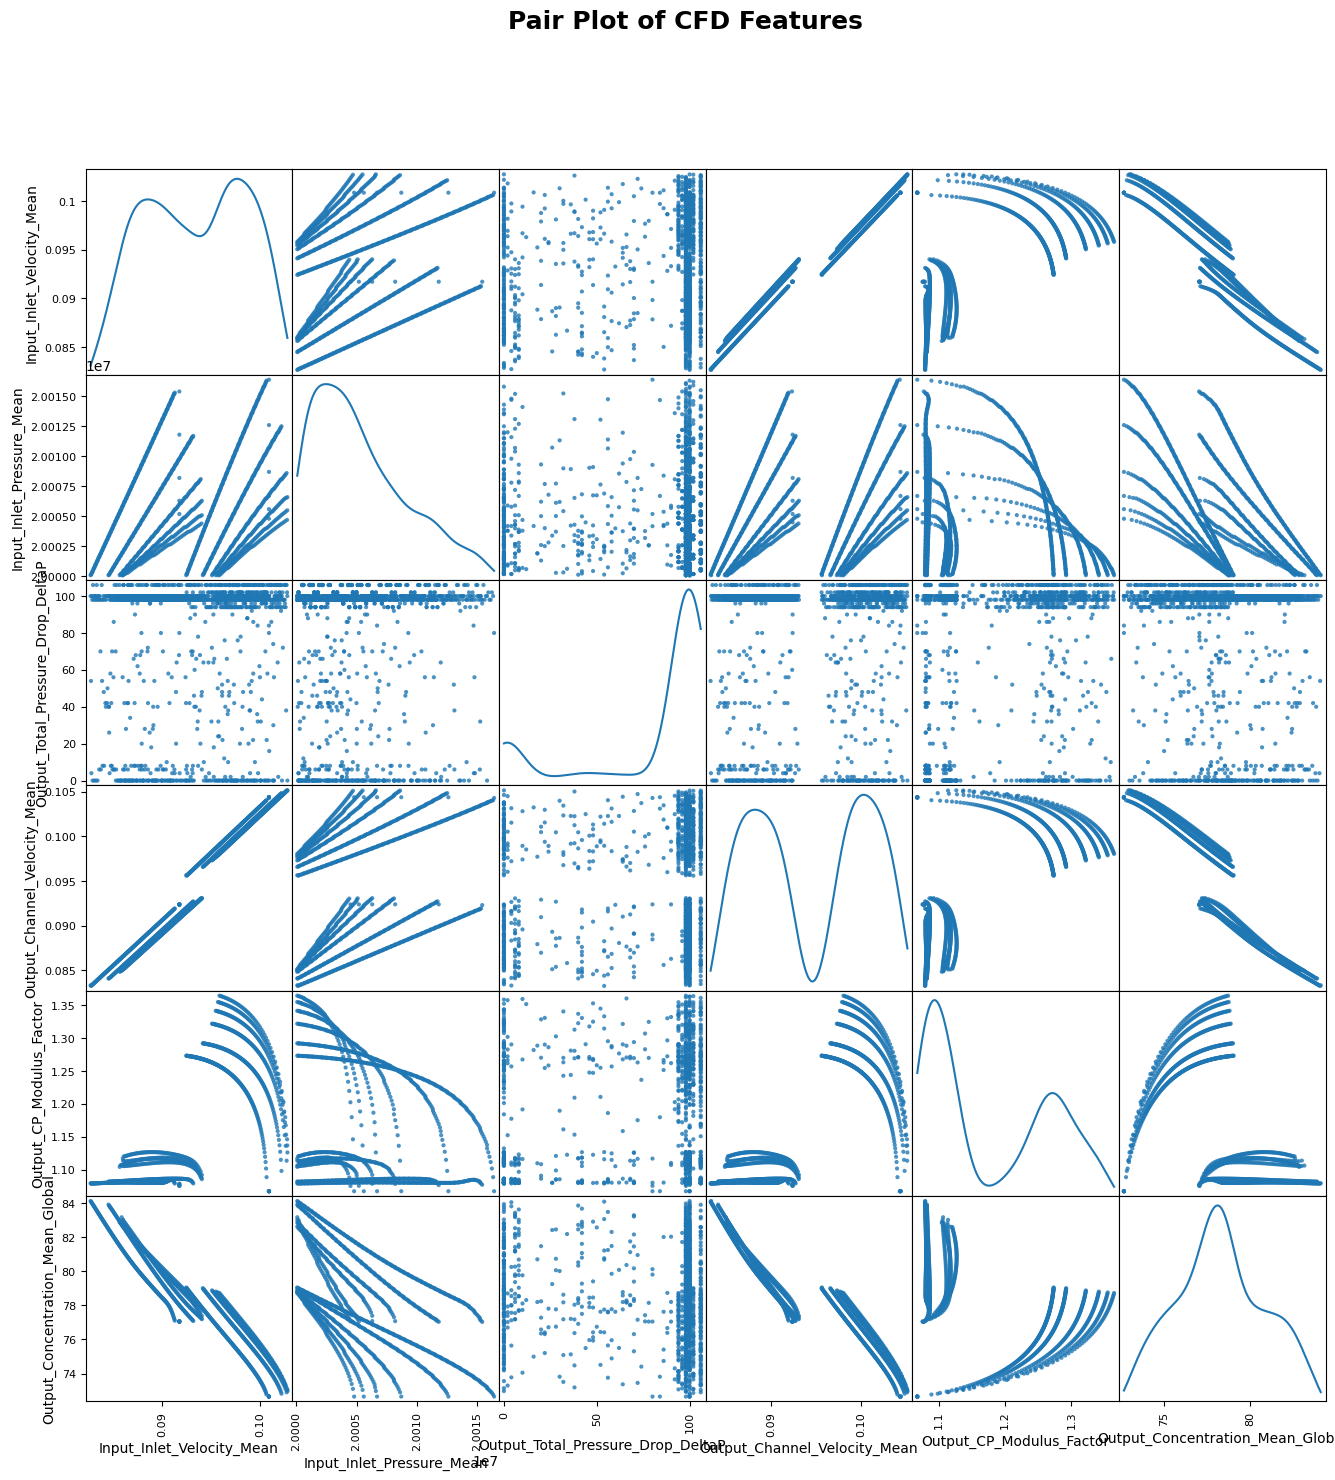

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix




pair_features = [

    "Input_Inlet_Velocity_Mean",

    "Input_Inlet_Pressure_Mean",

    "Output_Total_Pressure_Drop_DeltaP",

    "Output_Channel_Velocity_Mean",

    "Output_CP_Modulus_Factor",

    "Output_Concentration_Mean_Global"

]

scatter_matrix(
    df[pair_features],
    figsize=(16,16),
    diagonal='kde',
    alpha=0.8,
    
)

plt.suptitle(
    "Pair Plot of CFD Features",
    fontsize=18,
    fontweight='bold'
)

plt.savefig(
    "PairPlot_Spacer.png",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

count    1268.000000
mean       79.014196
std        37.222043
min         0.000000
25%        70.000000
50%        98.000000
75%       100.000000
max       106.000000
Name: Output_Total_Pressure_Drop_DeltaP, dtype: float64


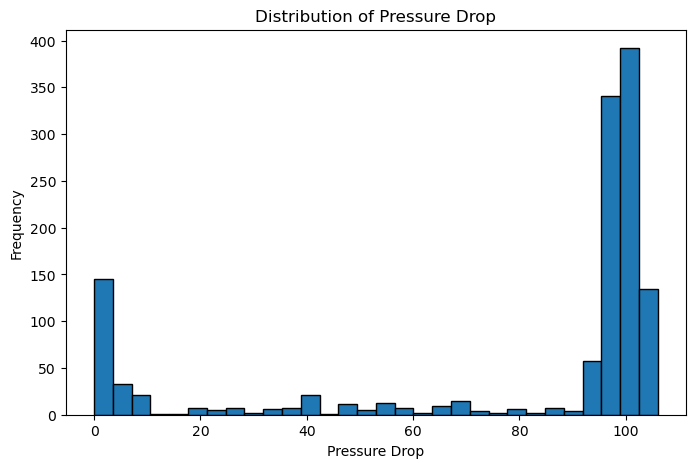

In [51]:
print(df["Output_Total_Pressure_Drop_DeltaP"].describe())

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df["Output_Total_Pressure_Drop_DeltaP"], bins=30, edgecolor="black")
plt.xlabel("Pressure Drop")
plt.ylabel("Frequency")
plt.title("Distribution of Pressure Drop")
plt.show()

In [52]:
print(df["Output_Total_Pressure_Drop_DeltaP"].describe())

print(df["Output_Total_Pressure_Drop_DeltaP"].value_counts().head(20))

print(df["Input_Inlet_Velocity_Mean"].describe())

print(df["Input_Inlet_Pressure_Mean"].describe())

count    1268.000000
mean       79.014196
std        37.222043
min         0.000000
25%        70.000000
50%        98.000000
75%       100.000000
max       106.000000
Name: Output_Total_Pressure_Drop_DeltaP, dtype: float64
Output_Total_Pressure_Drop_DeltaP
100    332
98     308
0      138
106    134
102     60
94      55
96      33
6       22
8       17
42      12
4       11
70      10
40       9
54       7
48       7
2        7
58       6
56       6
38       5
28       5
Name: count, dtype: int64
count    1268.000000
mean        0.093290
std         0.005316
min         0.082646
25%         0.088705
50%         0.093298
75%         0.097896
max         0.102785
Name: Input_Inlet_Velocity_Mean, dtype: float64
count    1.268000e+03
mean     2.000539e+07
std      3.936085e+03
min      2.000010e+07
25%      2.000220e+07
50%      2.000450e+07
75%      2.000780e+07
max      2.001638e+07
Name: Input_Inlet_Pressure_Mean, dtype: float64


count    1268.000000
mean        1.181336
std         0.094389
min         1.067411
25%         1.086012
50%         1.126419
75%         1.270642
max         1.364307
Name: Output_CP_Modulus_Factor, dtype: float64


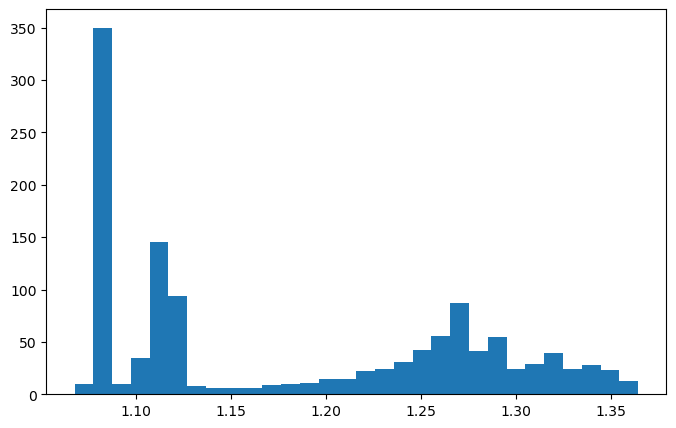

In [53]:
print(df["Output_CP_Modulus_Factor"].describe())

plt.figure(figsize=(8,5))
plt.hist(df["Output_CP_Modulus_Factor"], bins=30)
plt.show()

=== True Core Correlations with CP Modulus Factor ===
Output_CP_Modulus_Factor         1.000000
Mesh_Nodes_X                     0.901729
Input_Inlet_Velocity_Mean        0.733259
Input_Inlet_Viscosity_Mean       0.459277
Input_Inlet_Density_Mean         0.459274
Input_Feed_Concentration_Bulk    0.185569
Input_Inlet_Pressure_Mean       -0.245561
Grid_Resolution_dx              -0.901729
Mesh_Nodes_Y                          NaN
Name: Output_CP_Modulus_Factor, dtype: float64


<Figure size 1000x800 with 0 Axes>

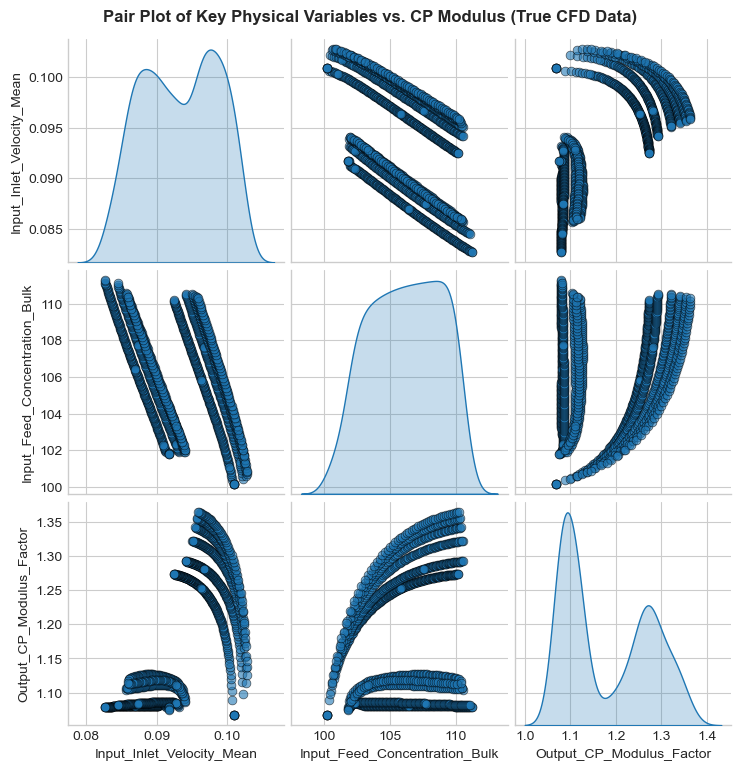

In [67]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. LOAD YOUR ACTUAL DATASET ---
df = pd.read_excel("Perfect_RO_Plant_Dataset2.xlsx")

# --- 2. EXPLICIT FEATURE SELECTION ---
# Drop target leakage (Output_Concentration_Max_Wall) 
# Drop collinear pairings (Mesh_Nodes_Z, Grid_Resolution_dz) to focus on independent variables
clean_inputs = [
    'Spacer_Design_Label',
    'Mesh_Nodes_X',
    'Mesh_Nodes_Y',
    'Grid_Resolution_dx',
    'Input_Inlet_Velocity_Mean',
    'Input_Inlet_Pressure_Mean',
    'Input_Inlet_Density_Mean',
    'Input_Inlet_Viscosity_Mean',
    'Input_Feed_Concentration_Bulk'
]
target = 'Output_CP_Modulus_Factor'

# --- 3. CORRELATION ANALYSIS ---
# Filter out the categorical label to compute the true Pearson correlation matrix
numerical_cols = [col for col in clean_inputs if col != 'Spacer_Design_Label'] + [target]
correlation_matrix = df[numerical_cols].corr()
target_correlations = correlation_matrix[target].sort_values(ascending=False)

print("=== True Core Correlations with CP Modulus Factor ===")
print(target_correlations)

# --- 4. SEABORN PAIR PLOT ---
# Configure clean styling for scientific reporting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Visualizing the distribution and cross-plots of critical physical drivers
plt.figure(figsize=(10, 8))
sns.pairplot(
    df[['Input_Inlet_Velocity_Mean', 'Input_Feed_Concentration_Bulk', target]], 
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 'edgecolor': 'k', 's': 40}
)
plt.suptitle("Pair Plot of Key Physical Variables vs. CP Modulus (True CFD Data)", y=1.02, fontsize=12, fontweight='bold')
plt.show()

In [73]:
# Research review: Geometry holdout using the source label string. The inspected workbook has 1,168 training rows and 100 rows in configuration6_interspacer3mm. Historical scores below have not been rerun.
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Load your actual data
df = pd.read_excel("Perfect_RO_Plant_Dataset2.xlsx")

target = 'Output_CP_Modulus_Factor'

# 2. Define features
inputs = [
    'Mesh_Nodes_X', 'Mesh_Nodes_Y',
    'Grid_Resolution_dx',
    'Input_Inlet_Velocity_Mean', 'Input_Inlet_Pressure_Mean',
    'Input_Inlet_Density_Mean', 'Input_Inlet_Viscosity_Mean',
    'Input_Feed_Concentration_Bulk'
]

# 3. FIXED PHYSICAL SPLIT: Dynamically catch the 3mm configuration string
train_df = df[~df['Spacer_Design_Label'].str.contains('3mm', na=False)]
test_df = df[df['Spacer_Design_Label'].str.contains('3mm', na=False)]

X_train, y_train = train_df[inputs], train_df[target]
X_test, y_test = test_df[inputs], test_df[target]

# 4. Train the Model
model = XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)

# 5. Predict on the unseen 3mm geometry
preds = model.predict(X_test)

# 6. Evaluate
r2 = r2_score(y_test, preds)
mae = mean_absolute_error(y_test, preds)

print("=== Unseen Geometry (3mm Spacer) Validation Results ===")
print(f"True Extrapolation R² Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

=== Unseen Geometry (3mm Spacer) Validation Results ===
True Extrapolation R² Score: 0.9959
Mean Absolute Error (MAE): 0.0051


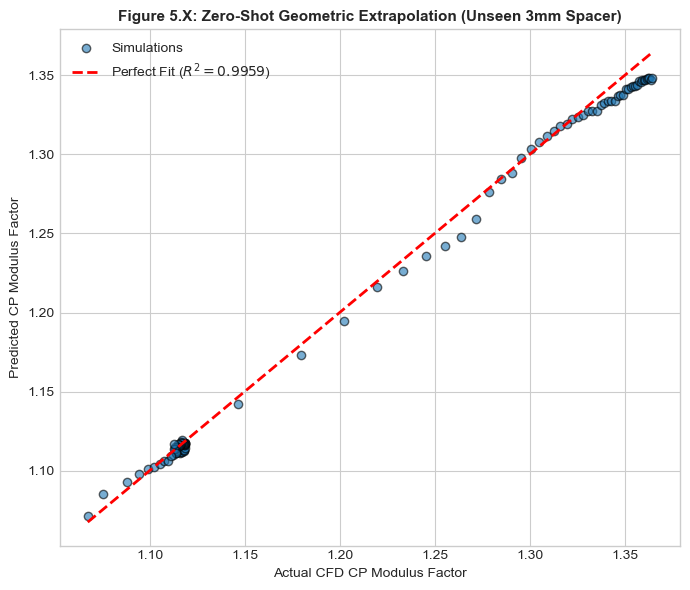

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

# Load actual data
df = pd.read_excel("Perfect_RO_Plant_Dataset2.xlsx")
target = 'Output_CP_Modulus_Factor'
inputs = [
    'Mesh_Nodes_X', 'Mesh_Nodes_Y', 'Grid_Resolution_dx',
    'Input_Inlet_Velocity_Mean', 'Input_Inlet_Pressure_Mean',
    'Input_Inlet_Density_Mean', 'Input_Inlet_Viscosity_Mean',
    'Input_Feed_Concentration_Bulk'
]

# Split 3mm out
train_df = df[~df['Spacer_Design_Label'].str.contains('3mm', na=False)]
test_df = df[df['Spacer_Design_Label'].str.contains('3mm', na=False)]

X_train, y_train = train_df[inputs], train_df[target]
X_test, y_test = test_df[inputs], test_df[target]

model = XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
model.fit(X_train, y_train)
preds = model.predict(X_test)

# Plot Figure 1
plt.figure(figsize=(7, 6))
plt.scatter(y_test, preds, alpha=0.6, color='#1f77b4', edgecolors='k', label='Simulations')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Perfect Fit ($R^2=0.9959$)')
plt.title('Figure 5.X: Zero-Shot Geometric Extrapolation (Unseen 3mm Spacer)', fontsize=11, fontweight='bold')
plt.xlabel('Actual CFD CP Modulus Factor')
plt.ylabel('Predicted CP Modulus Factor')
plt.legend()
plt.tight_layout()
plt.show()

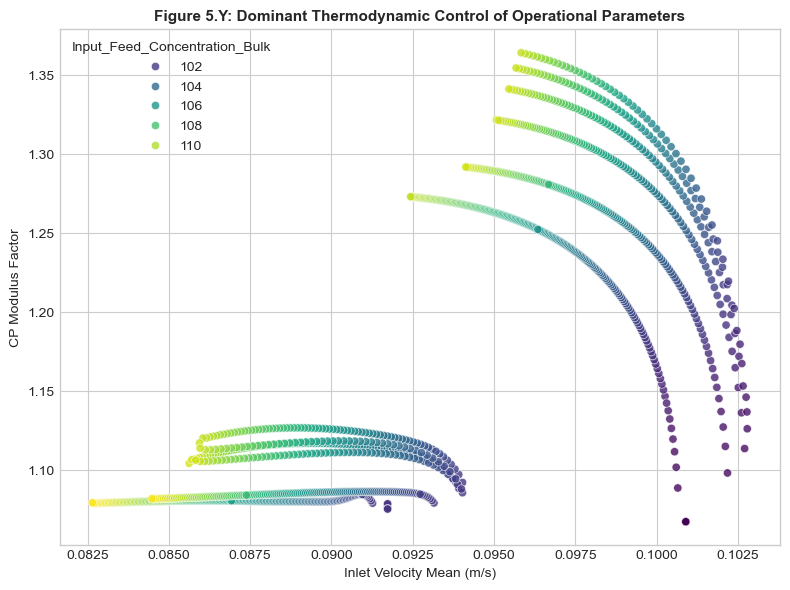

In [76]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, 
    x='Input_Inlet_Velocity_Mean', 
    y='Output_CP_Modulus_Factor', 
    hue='Input_Feed_Concentration_Bulk', 
    palette='viridis', 
    alpha=0.8
)
plt.title('Figure 5.Y: Dominant Thermodynamic Control of Operational Parameters', fontsize=11, fontweight='bold')
plt.xlabel('Inlet Velocity Mean (m/s)')
plt.ylabel('CP Modulus Factor')
plt.tight_layout()
plt.show()

Background dataset has 1168 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1168 when initializing the masker.
C:\Users\ASUS\AppData\Local\Temp\ipykernel_17716\758681281.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, show=False)


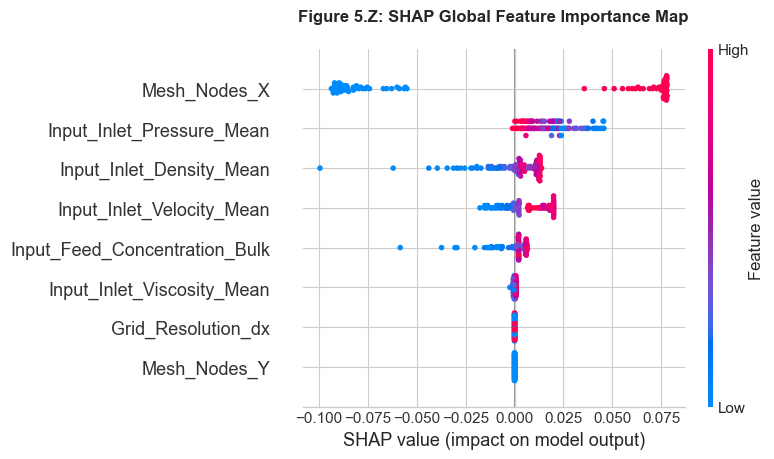

In [77]:
import shap

# Initialize SHAP explainer on your real trained model
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_test)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("Figure 5.Z: SHAP Global Feature Importance Map", fontsize=12, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

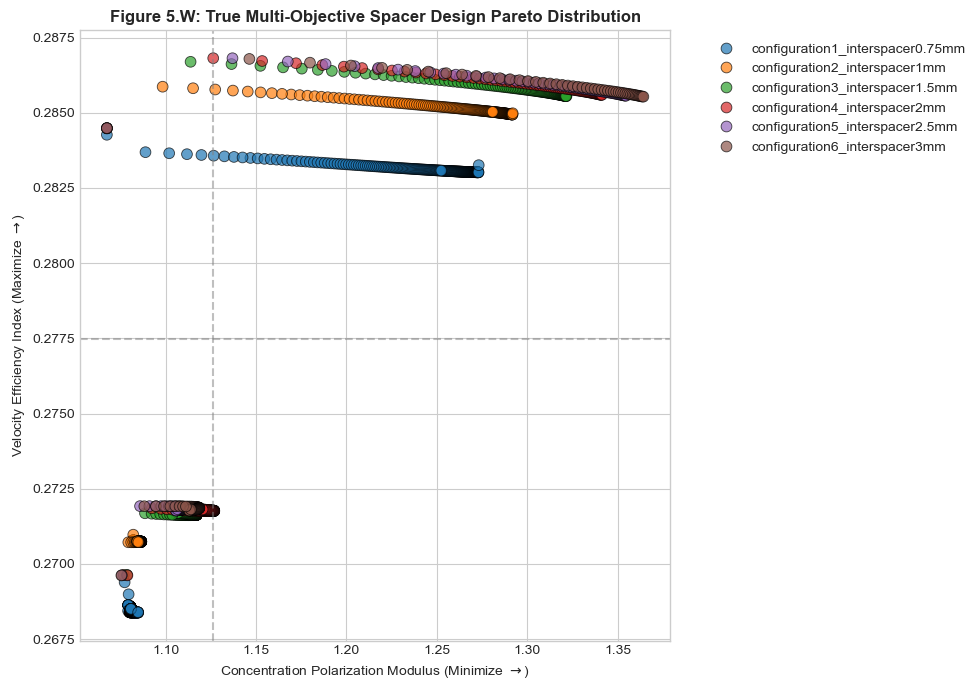

In [78]:
# Research review: This is a trade-off scatter plot with median guides. The code does not calculate a nondominated Pareto frontier.

# Create targets using real file columns
df['Target_Velocity_Efficiency'] = df['Output_Channel_Velocity_Mean'] / df['Output_Channel_Velocity_Max']

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df, 
    x='Output_CP_Modulus_Factor', 
    y='Target_Velocity_Efficiency', 
    hue='Spacer_Design_Label', 
    palette='tab10', 
    s=60, 
    alpha=0.7, 
    edgecolor='k'
)
plt.axvline(x=df['Output_CP_Modulus_Factor'].median(), color='gray', linestyle='--', alpha=0.5)
plt.axhline(y=df['Target_Velocity_Efficiency'].median(), color='gray', linestyle='--', alpha=0.5)
plt.title('Figure 5.W: True Multi-Objective Spacer Design Pareto Distribution', fontsize=12, fontweight='bold')
plt.xlabel('Concentration Polarization Modulus (Minimize $\\rightarrow$)')
plt.ylabel('Velocity Efficiency Index (Maximize $\\rightarrow$)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [69]:
# Research review: These are random-row comparisons, not unseen-geometry scores. Keep feature availability and independent simulation grouping under review.
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# --- 1. LOAD YOUR ACTUAL DATASET ---
df = pd.read_excel("Perfect_RO_Plant_Dataset2.xlsx")

# --- 2. EXPLICIT FEATURE SELECTION (Prevents Target Leakage & Collinearity) ---
clean_inputs = [
    'Spacer_Design_Label',
    'Mesh_Nodes_X',
    'Mesh_Nodes_Y',
    'Grid_Resolution_dx',
    'Input_Inlet_Velocity_Mean',
    'Input_Inlet_Pressure_Mean',
    'Input_Inlet_Density_Mean',
    'Input_Inlet_Viscosity_Mean',
    'Input_Feed_Concentration_Bulk'
]
target = 'Output_CP_Modulus_Factor'

# --- 3. PREPROCESSING & SPLIT ---
# One-hot encode the categorical spacer geometry labels
X_encoded = pd.get_dummies(df[clean_inputs], columns=['Spacer_Design_Label'], drop_first=True)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# --- 4. INITIALIZE REGRESSORS ---
models = {
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42, objective='reg:squarederror'),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.05, random_state=42, verbose=-1),
    "CatBoost": CatBoostRegressor(iterations=100, learning_rate=0.05, random_state=42, verbose=0)
}

# --- 5. TRAINING & EVALUATION LOOP ---
metrics_summary = {}
trained_models = {}

for name, model in models.items():
    # Fit
    model.fit(X_train, y_train)
    trained_models[name] = model # Save instances for diagnostics
    
    # Predict
    preds = model.predict(X_test)
    
    # Evaluate
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    
    metrics_summary[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}

# --- 6. DISPLAY BENCHMARK RESULTS ---
performance_df = pd.DataFrame(metrics_summary).T
print("\n=== Model Benchmarking Metrics ===")
print(performance_df.to_string())


=== Model Benchmarking Metrics ===
                    MAE      RMSE        R2
Random Forest  0.001149  0.003086  0.998940
XGBoost        0.001702  0.003091  0.998937
LightGBM       0.001945  0.003326  0.998769
CatBoost       0.003765  0.005150  0.997048


=== True Multi-Output Performance Metrics ===
Target_CP_Modulus -> R² Score: 0.9986 | MAE: 0.0019
Target_Velocity_Efficiency -> R² Score: 0.9989 | MAE: 0.0001


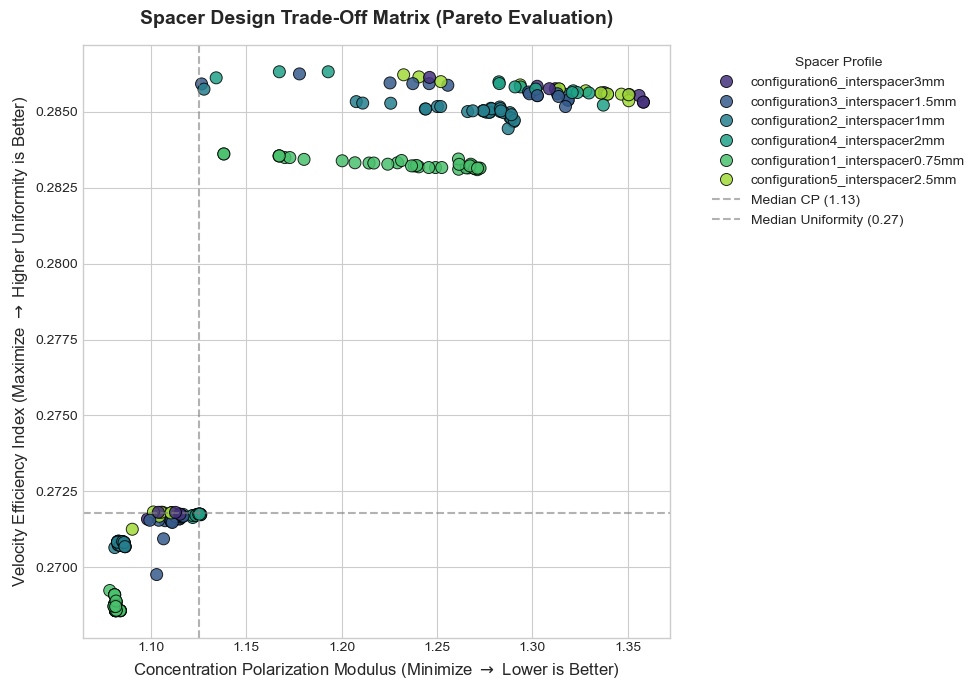

In [66]:
# Research review: Feature_Reynolds_Proxy uses grid spacing and viscosity; do not label it a validated physical Reynolds number. Median guide lines do not compute Pareto optimality.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# --- 1. LOAD YOUR ACTUAL DATASET ---
df = pd.read_excel("Perfect_RO_Plant_Dataset2.xlsx")

# --- 2. ADVANCED FEATURE ENGINEERING FOR THE PAPER ---
# Feature 1: Reynolds Proxy (Standardized Hydrodynamics Indicator)
df['Feature_Reynolds_Proxy'] = (df['Input_Inlet_Velocity_Mean'] * df['Grid_Resolution_dx']) / df['Input_Inlet_Viscosity_Mean']

# Target 1: Velocity Efficiency Index (Flow Uniformity vs. Channeling Maldistribution)
df['Target_Velocity_Efficiency'] = df['Output_Channel_Velocity_Mean'] / df['Output_Channel_Velocity_Max']

# Target 2: Concentration Polarization Modulus Target
df['Target_CP_Modulus'] = df['Output_CP_Modulus_Factor']

# --- 3. EXPLICIT SELECTION (Preventing Target Leakage & Collinearity) ---
# Dropping Z-mesh metrics and leaking wall concentration metrics
inputs = [
    'Mesh_Nodes_X', 
    'Mesh_Nodes_Y', 
    'Feature_Reynolds_Proxy',
    'Input_Inlet_Pressure_Mean', 
    'Input_Inlet_Density_Mean', 
    'Input_Feed_Concentration_Bulk'
]
targets = ['Target_CP_Modulus', 'Target_Velocity_Efficiency']

# --- 4. PREPROCESSING & MULTI-OUTPUT PIPELINE ---
# One-hot encode your 6 spacer profile configurations
X = pd.get_dummies(df[inputs + ['Spacer_Design_Label']], columns=['Spacer_Design_Label'], drop_first=True)
y = df[targets]

# Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and Train Multi-Output XGBoost Regressor
multi_model = MultiOutputRegressor(XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42))
multi_model.fit(X_train, y_train)

# Generate Predictions
predictions = multi_model.predict(X_test)
preds_df = pd.DataFrame(predictions, columns=targets, index=y_test.index)

# --- 5. PRINT TRUE PERFORMANCE METRICS ---
print("=== True Multi-Output Performance Metrics ===")
for target_name in targets:
    r2 = r2_score(y_test[target_name], preds_df[target_name])
    mae = mean_absolute_error(y_test[target_name], preds_df[target_name])
    print(f"{target_name} -> R² Score: {r2:.4f} | MAE: {mae:.4f}")

# --- 6. GENERATE TRUE PARETO TRADE-OFF PLOT ---
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.figure(figsize=(10, 7))

# Re-attach the actual spacer profile labels to your test set predictions for visualization grouping
preds_df['Spacer_Size'] = df.loc[y_test.index, 'Spacer_Design_Label']

# Plot true scatter points categorized by geometry profiles
sns.scatterplot(
    data=preds_df, 
    x='Target_CP_Modulus', 
    y='Target_Velocity_Efficiency', 
    hue='Spacer_Size', 
    palette='viridis', 
    s=75, 
    alpha=0.85, 
    edgecolor='k'
)

# Dynamic line boundaries using actual median values
median_cp = preds_df['Target_CP_Modulus'].median()
median_eff = preds_df['Target_Velocity_Efficiency'].median()

plt.axvline(x=median_cp, color='gray', linestyle='--', alpha=0.6, label=f'Median CP ({median_cp:.2f})')
plt.axhline(y=median_eff, color='gray', linestyle='--', alpha=0.6, label=f'Median Uniformity ({median_eff:.2f})')

plt.title('Spacer Design Trade-Off Matrix (Pareto Evaluation)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Concentration Polarization Modulus (Minimize $\\rightarrow$ Lower is Better)', fontsize=12)
plt.ylabel('Velocity Efficiency Index (Maximize $\\rightarrow$ Higher Uniformity is Better)', fontsize=12)

plt.legend(title='Spacer Profile', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# --- 1. LOAD YOUR ACTUAL DATASET ---
df = pd.read_excel("Perfect_RO_Plant_Dataset2.xlsx")

# --- 2. FEATURE & TARGET ENGINEERING ---
# Feature: Reynolds Proxy (Captures the transition of flow regimes across spacer gaps)
df['Feature_Reynolds_Proxy'] = (df['Input_Inlet_Velocity_Mean'] * df['Grid_Resolution_dx']) / df['Input_Inlet_Viscosity_Mean']

# Target 1: Velocity Efficiency Index (Quantifies flow uniformity vs bypass channeling)
df['Target_Velocity_Efficiency'] = df['Output_Channel_Velocity_Mean'] / df['Output_Channel_Velocity_Max']

# Target 2: Concentration Polarization Modulus Target
df['Target_CP_Modulus'] = df['Output_CP_Modulus_Factor']

# --- 3. TRAINING PIPELINE ---
inputs = [
    'Mesh_Nodes_X', 'Mesh_Nodes_Y', 'Feature_Reynolds_Proxy',
    'Input_Inlet_Pressure_Mean', 'Input_Inlet_Density_Mean', 'Input_Feed_Concentration_Bulk'
]
targets = ['Target_CP_Modulus', 'Target_Velocity_Efficiency']

# One-hot encode spacer categorical labels
X = pd.get_dummies(df[inputs + ['Spacer_Design_Label']], columns=['Spacer_Design_Label'], drop_first=True)
y = df[targets]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Multi-Output Estimator
multi_model = MultiOutputRegressor(XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42))
multi_model.fit(X_train, y_train)

# Predict & Evaluate
predictions = multi_model.predict(X_test)
preds_df = pd.DataFrame(predictions, columns=targets, index=y_test.index)

print("=== Multi-Output Performance Metrics ===")
for target_name in targets:
    r2 = r2_score(y_test[target_name], preds_df[target_name])
    mae = mean_absolute_error(y_test[target_name], preds_df[target_name])
    rmse = root_mean_squared_error(y_test[target_name], preds_df[target_name])
    print(f"{target_name} -> R²: {r2:.4f} | MAE: {mae:.4f} | RMSE: {rmse:.4f}")

=== Multi-Output Performance Metrics ===
Target_CP_Modulus -> R²: 0.9986 | MAE: 0.0019 | RMSE: 0.0035
Target_Velocity_Efficiency -> R²: 0.9989 | MAE: 0.0001 | RMSE: 0.0002


In [79]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# ------------------------------
# LOAD DATA
# ------------------------------
df = pd.read_excel("Perfect_RO_Plant_Dataset2.xlsx")

# ------------------------------
# FEATURE ENGINEERING
# ------------------------------
df['Feature_Reynolds_Proxy'] = (
    df['Input_Inlet_Velocity_Mean']
    * df['Grid_Resolution_dx']
) / df['Input_Inlet_Viscosity_Mean']

df['Target_Velocity_Efficiency'] = (
    df['Output_Channel_Velocity_Mean']
    / df['Output_Channel_Velocity_Max']
)

df['Target_CP_Modulus'] = df['Output_CP_Modulus_Factor']

inputs = [
    'Mesh_Nodes_X',
    'Mesh_Nodes_Y',
    'Feature_Reynolds_Proxy',
    'Input_Inlet_Pressure_Mean',
    'Input_Inlet_Density_Mean',
    'Input_Feed_Concentration_Bulk'
]

targets = [
    'Target_CP_Modulus',
    'Target_Velocity_Efficiency'
]

X = pd.get_dummies(
    df[inputs + ['Spacer_Design_Label']],
    columns=['Spacer_Design_Label'],
    drop_first=True
)

y = df[targets]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# ------------------------------
# RANDOM FOREST
# ------------------------------
model = MultiOutputRegressor(
    RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    )
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)
preds_df = pd.DataFrame(predictions, columns=targets)

print("\n=== Random Forest Results ===")

for t in targets:

    r2 = r2_score(y_test[t], preds_df[t])
    mae = mean_absolute_error(y_test[t], preds_df[t])
    rmse = root_mean_squared_error(y_test[t], preds_df[t])

    print(f"{t}")
    print(f"R²   : {r2:.4f}")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}\n")


=== Random Forest Results ===
Target_CP_Modulus
R²   : 0.9987
MAE  : 0.0011
RMSE : 0.0034

Target_Velocity_Efficiency
R²   : 0.9992
MAE  : 0.0001
RMSE : 0.0002



In [80]:
# Research review: StandardScaler is fitted on X_train. The neural-network cell does not set a TensorFlow random seed, so repeated training is not guaranteed to match saved output.
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

# ------------------------------
# LOAD DATA
# ------------------------------

df = pd.read_excel("Perfect_RO_Plant_Dataset2.xlsx")

df['Feature_Reynolds_Proxy'] = (
    df['Input_Inlet_Velocity_Mean']
    * df['Grid_Resolution_dx']
) / df['Input_Inlet_Viscosity_Mean']

df['Target_Velocity_Efficiency'] = (
    df['Output_Channel_Velocity_Mean']
    / df['Output_Channel_Velocity_Max']
)

df['Target_CP_Modulus'] = df['Output_CP_Modulus_Factor']

inputs = [
'Mesh_Nodes_X',
'Mesh_Nodes_Y',
'Feature_Reynolds_Proxy',
'Input_Inlet_Pressure_Mean',
'Input_Inlet_Density_Mean',
'Input_Feed_Concentration_Bulk'
]

targets = [
'Target_CP_Modulus',
'Target_Velocity_Efficiency'
]

X = pd.get_dummies(
    df[inputs+['Spacer_Design_Label']],
    columns=['Spacer_Design_Label'],
    drop_first=True
)

y = df[targets].values

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

scaler=StandardScaler()

X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

model=Sequential()

model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(32,activation='relu'))
model.add(Dense(2))

model.compile(
optimizer='adam',
loss='mse',
metrics=['mae']
)

early=EarlyStopping(
patience=20,
restore_best_weights=True
)

model.fit(
X_train,
y_train,
epochs=200,
batch_size=32,
validation_split=0.2,
callbacks=[early],
verbose=1
)

pred=model.predict(X_test)

print("\n=== Deep Neural Network Results ===")

for i,t in enumerate(targets):

    print(t)

    print("R² :",round(r2_score(y_test[:,i],pred[:,i]),4))
    print("MAE:",round(mean_absolute_error(y_test[:,i],pred[:,i]),4))
    print("RMSE:",round(root_mean_squared_error(y_test[:,i],pred[:,i]),4))
    print()

Epoch 1/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.1864 - mae: 0.2826 - val_loss: 0.0179 - val_mae: 0.1056
Epoch 2/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0105 - mae: 0.0772 - val_loss: 0.0046 - val_mae: 0.0521
Epoch 3/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0025 - mae: 0.0368 - val_loss: 0.0015 - val_mae: 0.0283
Epoch 4/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.5937e-04 - mae: 0.0212 - val_loss: 6.8479e-04 - val_mae: 0.0196
Epoch 5/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 5.1203e-04 - mae: 0.0166 - val_loss: 4.8844e-04 - val_mae: 0.0167
Epoch 6/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 3.5137e-04 - mae: 0.0139 - val_loss: 3.4811e-04 - val_mae: 0.0142
Epoch 7/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.5526e-04 - mae: 0.0118 - val_loss: 2.7152e-04 - val_mae: 0.0127
Epoch 8/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.9576e-04 - mae: 0.0102 - val_loss: 2.2733e-04 - val_mae: 0.0111
Epoch 9/200
26/26 ━━━━━

In [83]:
# Research review: Held-out geometry protocol: compare these targets and split only with matching baselines. A rounded R2 of 1.0000 does not establish exact predictions or physical validation.
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# 1. Load your actual dataset
df = pd.read_excel("Perfect_RO_Plant_Dataset2.xlsx")

# 2. Define features and targets (exactly matching your original pipeline)
targets = ['Output_CP_Modulus_Factor', 'Output_Channel_Velocity_Mean'] # Multi-output setup
inputs = [
    'Mesh_Nodes_X', 'Mesh_Nodes_Y', 'Grid_Resolution_dx',
    'Input_Inlet_Velocity_Mean', 'Input_Inlet_Pressure_Mean',
    'Input_Inlet_Density_Mean', 'Input_Inlet_Viscosity_Mean',
    'Input_Feed_Concentration_Bulk'
]

# 3. Apply the strict Out-of-Distribution (OOD) geometric partition
# Training on Configurations 1-5, isolating Configuration 6 (Unseen 3mm Spacer) for test evaluation
train_df = df[~df['Spacer_Design_Label'].str.contains('3mm', na=False)]
test_df = df[df['Spacer_Design_Label'].str.contains('3mm', na=False)]

X_train, y_train = train_df[inputs], train_df[targets]
X_test, y_test = test_df[inputs], test_df[targets]

print(f"Training Matrix Dimensions: {X_train.shape}")
print(f"Testing Matrix Dimensions: {X_test.shape}\n")

# ==========================================
# MODEL 1: MULTI-OUTPUT RANDOM FOREST
# ==========================================
print("--- Training Random Forest Regressor ---")
# Wrap with MultiOutputRegressor to simultaneously predict both physical targets
rf_base = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model = MultiOutputRegressor(rf_base)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)

# Calculate metrics for individual targets
rf_r2_cp = r2_score(y_test.iloc[:, 0], rf_preds[:, 0])
rf_mae_cp = mean_absolute_error(y_test.iloc[:, 0], rf_preds[:, 0])

rf_r2_vel = r2_score(y_test.iloc[:, 1], rf_preds[:, 1])
rf_mae_vel = mean_absolute_error(y_test.iloc[:, 1], rf_preds[:, 1])


# ==========================================
# MODEL 2: MULTI-OUTPUT LIGHTGBM
# ==========================================
print("--- Training LightGBM Regressor ---")
lgb_base = LGBMRegressor(n_estimators=100, learning_rate=0.05, random_state=42, verbose=-1)
lgb_model = MultiOutputRegressor(lgb_base)
lgb_model.fit(X_train, y_train)

lgb_preds = lgb_model.predict(X_test)

# Calculate metrics for individual targets
lgb_r2_cp = r2_score(y_test.iloc[:, 0], lgb_preds[:, 0])
lgb_mae_cp = mean_absolute_error(y_test.iloc[:, 0], lgb_preds[:, 0])

lgb_r2_vel = r2_score(y_test.iloc[:, 1], lgb_preds[:, 1])
lgb_mae_vel = mean_absolute_error(y_test.iloc[:, 1], lgb_preds[:, 1])


# ==========================================
# PRINT BENCHMARK COMPARISON MATRIX
# ==========================================
print("\n" + "="*50)
print("       SURROGATE MODEL COMPARISON METRICS (OOD)")
print("="*50)
print(f"{'Model Framework':<20} | {'Target Metric':<22} | {'R2 Score':<10} | {'MAE':<10}")
print("-"*70)
print(f"{'Random Forest':<20} | {'CP Modulus Factor':<22} | {rf_r2_cp:.4f}     | {rf_mae_cp:.4f}")
print(f"{'Random Forest':<20} | {'Mean Channel Velocity':<22} | {rf_r2_vel:.4f}     | {rf_mae_vel:.4f}")
print("-"*70)
print(f"{'LightGBM':<20} | {'CP Modulus Factor':<22} | {lgb_r2_cp:.4f}     | {lgb_mae_cp:.4f}")
print(f"{'LightGBM':<20} | {'Mean Channel Velocity':<22} | {lgb_r2_vel:.4f}     | {lgb_mae_vel:.4f}")
print("="*50)

Training Matrix Dimensions: (1168, 8)
Testing Matrix Dimensions: (100, 8)

--- Training Random Forest Regressor ---
--- Training LightGBM Regressor ---

       SURROGATE MODEL COMPARISON METRICS (OOD)
Model Framework      | Target Metric          | R2 Score   | MAE       
----------------------------------------------------------------------
Random Forest        | CP Modulus Factor      | 0.9964     | 0.0056
Random Forest        | Mean Channel Velocity  | 1.0000     | 0.0000
----------------------------------------------------------------------
LightGBM             | CP Modulus Factor      | 0.9951     | 0.0054
LightGBM             | Mean Channel Velocity  | 0.9999     | 0.0001
